# Analysis of data from muscle cross sections using LISA analysis tools

Michael Rariden, mr2ep@virginia.edu, 1JAN25

# Start here

In [15]:
import networkx as nx
import anndata as ad
import scanpy as sc
import squidpy as sq

import re
from pathlib import Path 
from tqdm import tqdm
from scipy.sparse import csr_matrix


adata_files = list(Path("/scratch/hyt6ex/RBT/output/").glob("*h5ad"))
print(f"Total matching files found: {len(adata_files)}")

adata_list = []
for adata_file in tqdm(adata_files):
    if adata_file.name.startswith("Aim"):
        adata_i = ad.read_h5ad(adata_file)
        adata_list.append(adata_i)
adata_i
# print(adata_list)


Total matching files found: 66


100%|██████████| 66/66 [00:21<00:00,  3.03it/s]


AnnData object with n_obs × n_vars = 10780 × 12
    obs: 'label', 'centroid-0', 'centroid-1', 'section_fname', 'LISA-minFD', 'LISA-eccentricity', 'MP_clustering_1step_5c'
    uns: 'LISA-minFD_HH_distance_deciles', 'LISA-minFD_HH_distance_dispersion', 'LISA-minFD_HH_distance_median', 'LISA-minFD_HL_distance_deciles', 'LISA-minFD_HL_distance_dispersion', 'LISA-minFD_HL_distance_median', 'LISA-minFD_LH_distance_deciles', 'LISA-minFD_LH_distance_dispersion', 'LISA-minFD_LH_distance_median', 'LISA-minFD_LL_distance_deciles', 'LISA-minFD_LL_distance_dispersion', 'LISA-minFD_LL_distance_median', 'LISA-minFD_ns_distance_deciles', 'LISA-minFD_ns_distance_dispersion', 'LISA-minFD_ns_distance_median', 'MP_clustering_distance', 'delaunay_neighbors', 'lisa_distance_dict', 'spatial'
    obsm: 'spatial'
    obsp: 'delaunay_connectivities', 'delaunay_distances'
    layers: None (.X)

In [16]:
adata_list[1].uns['spatial']

{'Aim1c_LG_NR03_expt_s2c1-3_cp_masks': {'images': {'hires': '/scratch/hyt6ex/RBT/original_images/Aim1c_LG_NR03_expt_s2c1-3.tif'},
  'masks_paths': {'fiber_masks_path': '/scratch/hyt6ex/RBT/fiber_masks/Aim1c_LG_NR03_expt_s2c1-3_cp_masks.png',
   'nuclei_masks_path': 'None'},
  'scalefactors': {'tissue_hires_scalef': 0.65}}}

In [17]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

Image.MAX_IMAGE_PIXELS = None

def open_image(fname: str) -> np.array:
    img = Image.open(fname)

    img_arr = []
    for i in range(3):
        img.seek(i)  # skip to the second frame
        img_arr.append(np.array(img))
    img_arr = np.array(img_arr).transpose((1, 2, 0))
    
    return img_arr


In [18]:
def open_mask(fname:str) -> np.array:
    mask_arr = np.array(Image.open(fname))
    colors = np.random.randint(0, 255, size=(np.max(mask_arr)+1, 3))
    colors[0] = [0, 0, 0]

    colored_mask_arr = colors[mask_arr]
    return colored_mask_arr


In [19]:
show_masks = False 

if show_masks == True:

    for ad_i in adata_list:
        image_file = next(iter(ad_i.uns['spatial'].values()))['images']['hires']
        mask_file = next(iter(ad_i.uns['spatial'].values()))['masks_paths']['fiber_masks_path']

        mask_img = open_mask(mask_file)
        image_img = open_image(image_file)

        fig, ax = plt.subplots(1, 1, figsize=(10,10))
        _ = ax.imshow(image_img)
        _ = ax.imshow(mask_img, alpha=.5)

        ax.set_title(mask_file.split('/')[-1])
        ax.axis('off')
        plt.show()
        

In [20]:
print("Section file name" + '\t'*3 + 'fiber count' + '\t' + 'index')
print('-' * 60)
for i, ad_i in enumerate(adata_list):
    print(ad_i.obs['section_fname'].unique()[0] + '\t' + str(len(ad_i)) + 2*'\t' + str(i))

Section file name			fiber count	index
------------------------------------------------------------
Aim1c_LG_BP03_expt_s1c1-3	6652		0
Aim1c_LG_NR03_expt_s2c1-3	10866		1
Aim1c_LG_NR12_ctrl_extra_s2c1-3	11040		2
Aim1c_LG_BP02_ctrl_s1c1-3	7423		3
Aim1c_LG_NR16_ctrl_s2c1-3	13612		4
Aim1c_LG_CG20_expt_s1c1-3	6186		5
Aim1c_LG_NR13_expt_extra_s2c1-3	6174		6
Aim1c_LG_CG09_ctrl_s2c1-3	8155		7
Aim1c_LG_NR14_expt_extra_s2c1-3	9187		8
Aim1c_LG_CG21_ctrl_s1c1-3	7940		9
Aim1c_LG_NR05_ctrl_s1c1-3	10330		10
Aim1c_LG_CG12_ctrl_s2c1-3	10503		11
Aim1c_LG_NR16_expt_s1c1-3	9017		12
Aim1c_LG_CG15_expt-1_s4c1-3	9241		13
Aim1c_LG_CG20_ctrl_s3c1-3	12909		14
Aim1c_LG_CG13_expt_s2c1-3	6524		15
Aim1c_LG_NR01_ctrl_s2c1-3	13855		16
Aim1c_LG_NR07_expt_s3c1-3	10461		17
Aim1c_LG_NR05_expt_s3c1-3	12071		18
Aim1c_LG_CG10_ctrl_s1c1-3	12505		19
Aim1c_LG_BP04_expt_s1c1-3	4412		20
Aim1c_LG_NR06_expt_s1c1-3	9561		21
Aim1c_LG_CG14_ctrl_s2c1-3	9470		22
Aim1c_LG_CG17_ctrl_s1c1-3	13147		23
Aim1c_LG_BP05_expt_s3c1-3	9946		24
Aim1c

In [21]:
specific_sections = [
    'Aim1c_LG_BP01_ctrl_s1c1-3',
    'Aim1c_LG_BP01_expt_s1c1-3',
    'Aim1c_LG_CG06_ctrl_s3c1-3',
    'Aim1c_LG_CG06_expt_s3c1-3',
    'Aim1c_LG_CG17_ctrl_s1c1-3',
    'Aim1c_LG_CG17_expt_s3c1-3',
    'Aim1c_LG_NR11_ctrl_extra_s1c1-3',
    'Aim1c_LG_NR11_expt_extra_s3c1-3'
]
specific_idx = []
for i, ad_i in enumerate(adata_list):
    if ad_i.obs['section_fname'].iloc[0] in specific_sections:
        specific_idx.append(i)
        
specific_idx

[23, 25, 29, 33, 43, 47, 57, 58]

/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


23 Aim1c_LG_CG17_ctrl_s1c1-3 13147 fibers


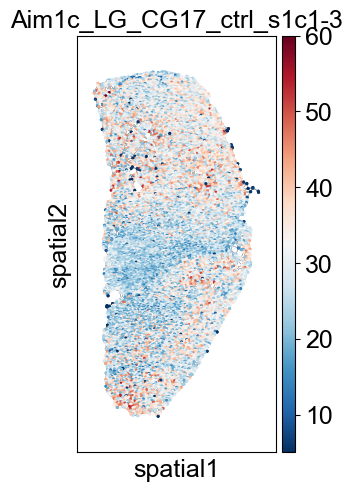

25 Aim1c_LG_NR11_ctrl_extra_s1c1-3 13089 fibers


/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


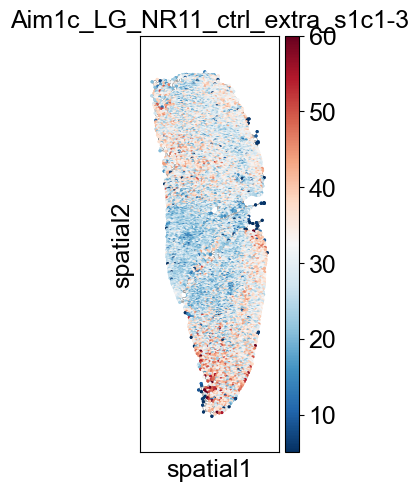

29 Aim1c_LG_CG17_expt_s3c1-3 8654 fibers


/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


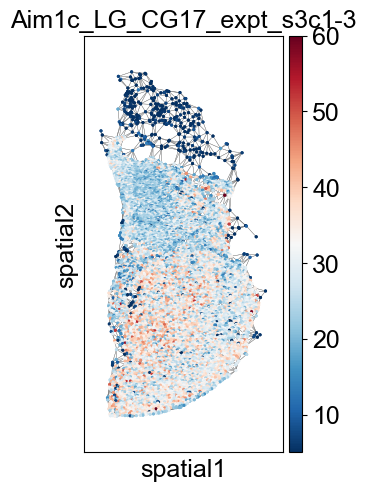

33 Aim1c_LG_BP01_expt_s1c1-3 5173 fibers


/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


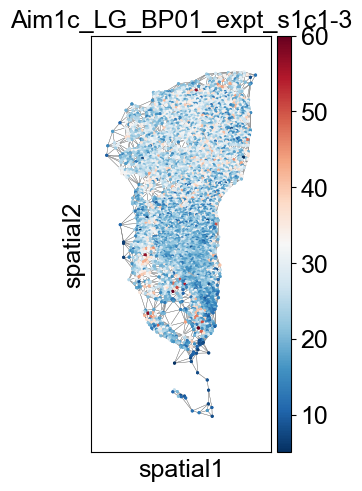

43 Aim1c_LG_CG06_expt_s3c1-3 6934 fibers


/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


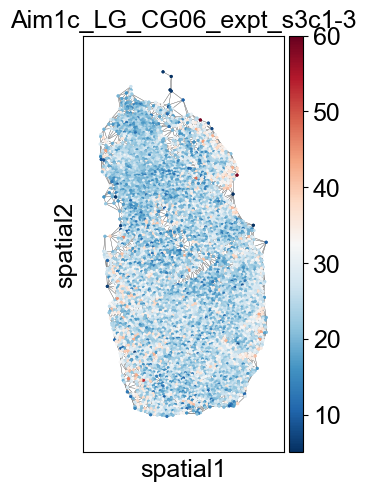

47 Aim1c_LG_CG06_ctrl_s3c1-3 12349 fibers


/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


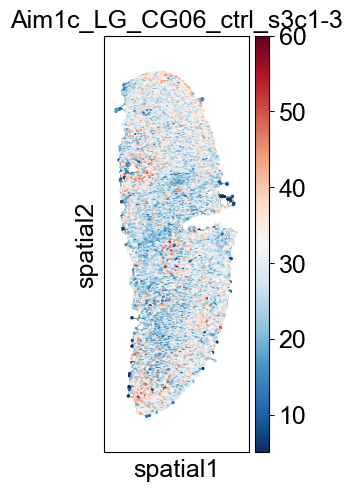

57 Aim1c_LG_BP01_ctrl_s1c1-3 11790 fibers


/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


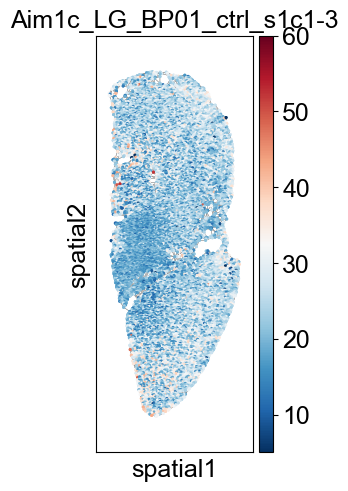

58 Aim1c_LG_NR11_expt_extra_s3c1-3 6464 fibers


/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


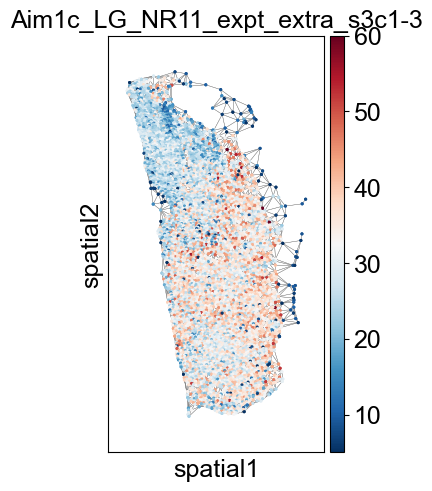

In [22]:
for i in specific_idx: 
    ad_i = adata_list[i] 
    section_name = ad_i.obs['section_fname'].iloc[0]
    print(i, section_name, f'{ad_i.n_obs} fibers')

    sq.pl.spatial_scatter(ad_i, 
                          color='minFD', 
                          shape=None,
                          size=6,
                          size_key='tissue_hires_scalef',
                          library_key='section_fname',
                          title=section_name, #new variable
                          #title='VML Injury',
                          cmap='RdBu_r',
                          connectivity_key='delaunay_connectivities',
                          edges_width=.25,
                          vmin=5,    
                          vmax=60,
                         )
    plt.show()


In [23]:
adata_list[0].var_names

Index(['area', 'eccentricity', 'perimeter', 'minFD', 'feret_diameter_max',
       'moments_hu-0', 'moments_hu-1', 'moments_hu-2', 'moments_hu-3',
       'moments_hu-4', 'moments_hu-5', 'moments_hu-6'],
      dtype='str')

In [24]:
# Define your font settings here
font_setting = {
    'size': 18,  # Example font size
    'family': 'Arial',  # Example font family
}

# Set the global font size for larger elements like labels and titles
plt.rc('axes', titlesize=font_setting['size'])  # fontsize of the axes title
plt.rc('axes', labelsize=font_setting['size'])  # fontsize of the x and y labels
plt.rc('xtick', labelsize=font_setting['size'])  # fontsize of the tick labels
plt.rc('ytick', labelsize=font_setting['size'])  # fontsize of the tick labels
plt.rc('legend', fontsize=font_setting['size'])  # legend fontsize
plt.rc('font', size=font_setting['size'], family=font_setting['family'])  # default font size and family


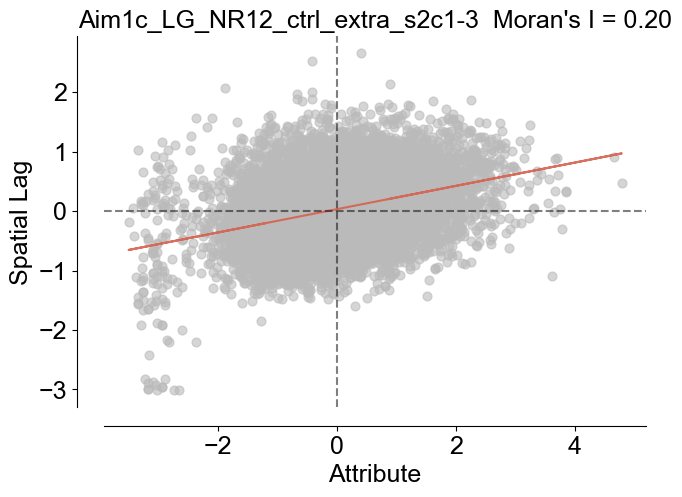

In [25]:
import sys
sys.path.insert(0, '/scratch/hyt6ex/fibcon-main') # so `from utils import ...` finds Fibcon's utils.py


from libpysal.weights import W, lag_spatial
from esda.moran import Moran, Moran_Local
from splot.esda import moran_scatterplot


from utils import get_graph_W, calculate_LISA # get_graph_moran, make_moran_scatterplot are not in this utils.py


# LISA labels are already stored in each .h5ad by the batch job.
# Uncommenting the next line recomputes them for one section and overwrites that section's labels in memory.
# calculate_LISA(adata_list[2], 'num_cln', neighbors_key='delaunay_neighbors')   # needs nuclei masks; not in RBT data
# calculate_LISA(adata_list[2], 'minFD', neighbors_key='delaunay_neighbors')


# replaces make_moran_scatterplot: global Moran's I scatterplot for one section
ad_i = adata_list[2]
G_i = nx.Graph(ad_i.obsp[ad_i.uns['delaunay_neighbors']['connectivities_key']])
w_i = get_graph_W(G_i)
y_i = ad_i[:, ['minFD']].to_df().values.flatten()

moran_i = Moran(y_i, w_i)
fig, ax = moran_scatterplot(moran_i)
ax.set_title(f"{ad_i.obs['section_fname'].iloc[0]}  Moran's I = {moran_i.I:.2f}")
plt.show()

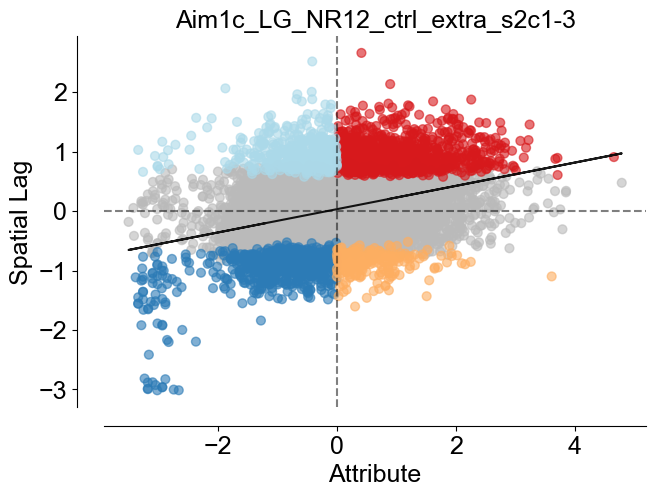

In [26]:
# from utils import visualize_moran_scatter          # not in this utils.py
#
# adata_moran = get_graph_moran(adata_list[1], feature='minFD')
# visualize_moran_scatter(adata_moran)
# plt.show()

# Local Moran (LISA) scatterplot (replaces get_graph_moran + visualize_moran_scatter)
moran_loc_i = Moran_Local(y_i, w_i)
fig, ax = moran_scatterplot(moran_loc_i, p=0.05)
ax.set_title(ad_i.obs['section_fname'].iloc[0])
plt.show()


# adata_moran = get_graph_moran(adata_list[44], feature='minFD')
# visualize_moran_scatter(adata_moran)
# plt.show()


In [27]:
def plot_LISA(adata, feature, size=5, size_key='tissue_hires_scalef', library_key='section_fname', title=None, ax=None):
    from matplotlib.colors import ListedColormap

    color_dict = { 
        "HH": "#d7191c",
        "LH": "#0066ff",
        "LL": "#000099",
        "HL": "#ff9933",
        "ns": "lightgrey",
    }

    color_list = [color_dict[label] for label in sorted(color_dict.keys())] 
    listed_colormap = ListedColormap(color_list)
    
    color = ''
    if "LISA" in feature:
        color = feature
    else: 
        color = "LISA-" + feature
        
    if not title:
        title = next(iter(adata.uns['spatial']))

    sq.pl.spatial_scatter(adata, 
                          color=color, 
                          shape=None,
                          size=5,
                          size_key='tissue_hires_scalef',
                          library_key='section_fname',
                          title=title,
                          palette=listed_colormap,
                          ax=ax,
                          
                          # # This was emperically determined and checked against the original images
                          # scalebar_dx=0.345,
                          # scale_factor=8.6,
                          # scalebar_kwargs={'location':"upper right"}   
                         )


/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


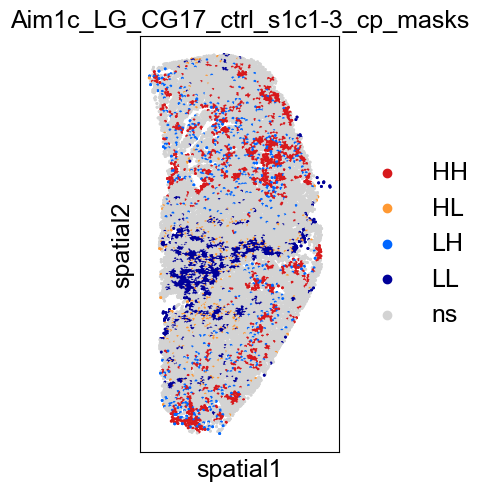

/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


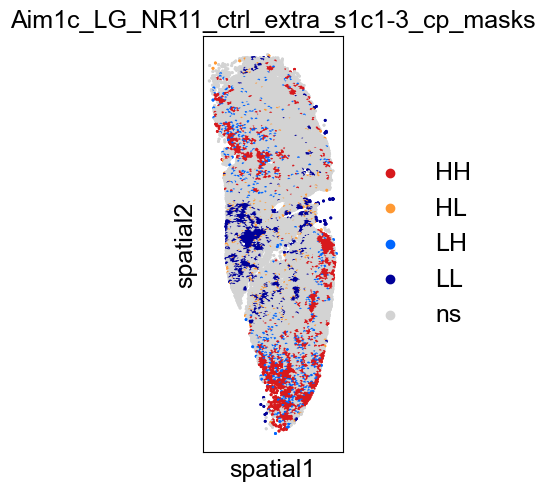

/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


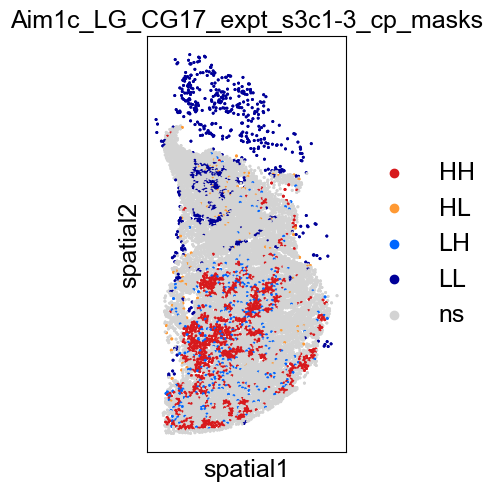

/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


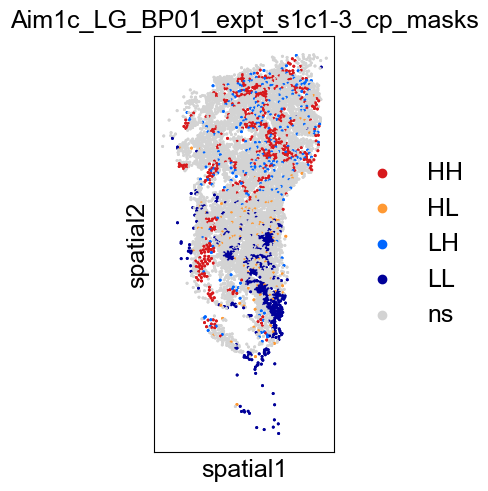

/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


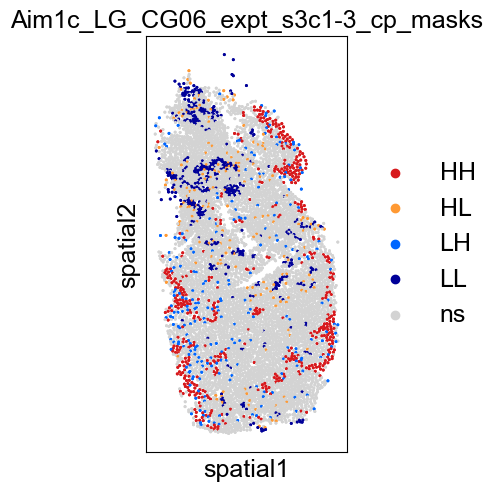

/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


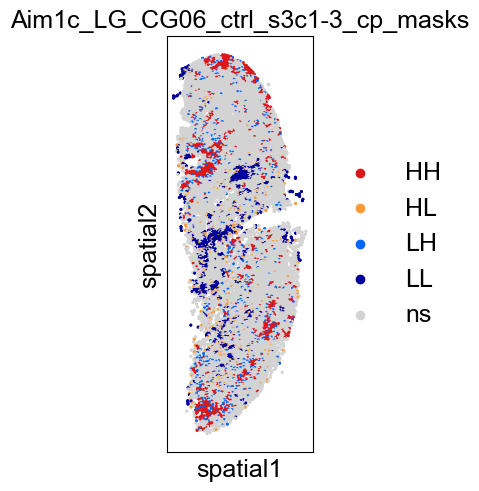

/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


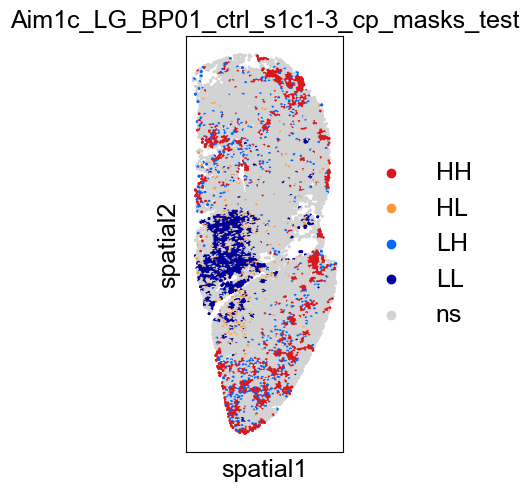

/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/hyt6ex/.local/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


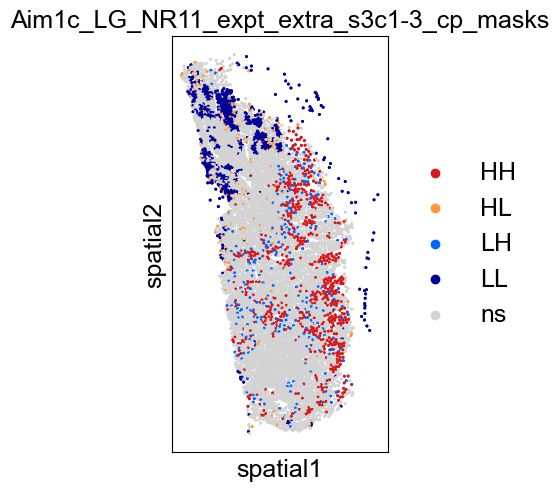

In [28]:
for i in specific_idx:
    plot_LISA(adata_list[i], 'minFD',)
    plt.show()



In [29]:
ad_keep_dict = {}

for ad_i in adata_list:
    ad_full_name = ad_i.obs['section_fname'].iloc[0]
    ad_name_parts = ad_full_name.split("_")
    ad_name = '_'.join(ad_name_parts[:3])
    
    (ad_keep_value, _) = ad_keep_dict.get(ad_name, (0, ''))
    if ad_i.n_obs > ad_keep_value:
        ad_keep_dict[ad_name] = (ad_i.n_obs, ad_i.obs['section_fname'].iloc[0])
        
ad_keep_dict

print(f'Number of images after: {len(adata_list)}')
print(f'Number of images after: {len(ad_keep_dict)}')

Number of images after: 66
Number of images after: 37


In [30]:
# use that to keep only the sections with highest # of fibers
keep_names = [x for _, x in ad_keep_dict.values()]
adata_short_list = []
for ad_i in adata_list:
    this_name = ad_i.obs['section_fname'].iloc[0]
    if this_name in keep_names:
        adata_short_list.append(ad_i)

print(len(adata_short_list))

37


In [31]:
import pickle

# Save list to pickle 
list_pkl_file = '/scratch/hyt6ex/AIM1C_laminin_all/ad_shortlist.pkl'
with open(list_pkl_file, 'wb') as f:
    pickle.dump(adata_short_list, f)


FileNotFoundError: [Errno 2] No such file or directory: '/scratch/hyt6ex/AIM1C_laminin_all/ad_shortlist.pkl'

In [ ]:
LG_categories = {


In [ ]:
adatas = ad.concat(adata_short_list, merge='same', uns_merge='first')
adatas.obs['section_fname'] = adatas.obs['section_fname'].astype('category')
adatas.obs_names_make_unique()

# def sort_condition(section_fname):
#     if 'ctrl' in section_fname.lower():
#         return 'CTRL'
#     if '_l_' in section_fname.lower():
#         return 'CTRL'
#     if 'expt' in section_fname.lower():
#         return 'EXP'
#     if '_t_' in section_fname.lower():
#         return 'EXP'

def get_animal(section_fname):
    # Aim1c_LG_BP01_ctrl_s1c1-3 -> BP01
    return section_fname.split('_')[2]

def get_group(animal_name):
    # BP01 -> BP -> group_names['BP']
    prefix = re.match(r'[A-Za-z]+', animal_name).group()
    return group_names.get(prefix, prefix)

def sort_condition(section_fname):
    if 'ctrl' in section_fname.lower():
        return 'CTRL'
    if 'exp' in section_fname.lower():
        return 'EXP'
    
adatas_df = adatas.to_df()
adatas_df['section_fname'] = adatas.obs['section_fname']
adatas_df['condition'] = adatas_df['section_fname'].map(lambda x: sort_condition(x))
adatas_df['muscle'] = adatas_df['section_fname'].map(lambda x: 'TA' if 'ta' in x.lower() else 'LGN')
adatas_df['animal_name'] = adatas_df['section_fname'].map(lambda x: x.split('_')[0])
adatas_df['group'] = adatas_df['animal_name'].map(baa_categories)
adatas_df['LISA-minFD'] = adatas.obs['LISA-minFD']
adatas_df.head()

adatas.write_h5ad('/scratch/hyt6ex/AIM1C_laminin_all/all_sections_adata.h5ad')

In [ ]:
adatas_df.groupby('group')['animal_name'].count()

# Start here for loading datat from file:

In [ ]:
baa_categories = {
    'BAA01' : 'LGN TEMR',
    'BAA02' : 'LGN TEMR',
    'BAA03' : 'LGN TEMR',
    'BAA04' : 'LGN TEMR',
    'BAA05' : 'LGN TEMR',
    'BAA06' : 'LGN TEMR',
    'BAA07' : 'LGN TEMR',
    'BAA08' : 'LGN TEMR',
    'BAA09' : 'TAPoly TEMR',
    'BAA10' : 'TAPoly TEMR',
    'BAA11' : 'TAPoly TEMR',
    'BAA12' : 'TAPoly TEMR',
    'BAA13' : 'LGNPoly TEMR',
    'BAA14' : 'LGNPoly TEMR',
    'BAA15' : 'LGNPoly TEMR',
    'BAA16' : 'LGNPoly TEMR',
    'BAA17' : 'LGNPoly TEMR',
    'BAA18' : 'LGNPoly TEMR',
    'BAA19' : 'LGNPoly TEMR',
    'BAA20' : 'LGNPoly TEMR',
    'BAA21' : 'TAPoly TEMR',
    'BAA22' : 'TAPoly TEMR',
    'BAA23' : 'TAPoly TEMR',
    'BAA24' : 'TAPoly TEMR',
    'BAA25' : 'TA TEMR',
    'BAA26' : 'TA TEMR',
    'BAA27' : 'TA TEMR',
    'BAA28' : 'TA TEMR',
    'BAA29' : 'TA TEMR',
    'BAA30' : 'TA TEMR',
    'BAA31' : 'TA TEMR',
    'BAA32' : 'TA TEMR',
    'TAPoly01' : 'TAPoly',
    'TAPoly02' : 'TAPoly',
    'TAPoly03' : 'TAPoly',
    'TAPoly04' : 'TAPoly',
    'TAPoly05' : 'TAPoly',
    'TAPoly06' : 'TAPoly',
    'TANR07' : 'TANR',
    'TANR08' : 'TANR',
    'PPN05' : 'PPN',
    'PPN06' : 'PPN',
    'CTRL07' : 'CTRL',
    'CTRL08' : 'CTRL',
}

In [ ]:
import anndata as ad
import numpy as np
import seaborn as sns
import pandas as pd


adatas = ad.read_h5ad('/scratch/mr2ep/BAA_LAD_all/all_sections_adata.h5ad')
def sort_condition(section_fname):
    if 'ctrl' in section_fname.lower():
        return 'CTRL'
    if '_l_' in section_fname.lower():
        return 'CTRL'
    if 'exp' in section_fname.lower():
        return 'EXP'
    if '_r_' in section_fname.lower():
        return 'EXP'
    
    
adatas_df = adatas.to_df()
adatas_df['section_fname'] = adatas.obs['section_fname']
adatas_df['condition'] = adatas_df['section_fname'].map(lambda x: sort_condition(x))
adatas_df['muscle'] = adatas_df['section_fname'].map(lambda x: 'TA' if 'ta' in x.lower() else 'LGN')
adatas_df['animal_name'] = adatas_df['section_fname'].map(lambda x: x.split('_')[0])
adatas_df['group'] = adatas_df['animal_name'].map(baa_categories)
adatas_df['LISA-minFD'] = adatas.obs['LISA-minFD']
adatas_df.head()

In [ ]:
# sort data 
median_df = adatas_df.groupby(['muscle', 'animal_name', 'condition',  'group'])['minFD'].median().to_frame()
median_df.reset_index(inplace=True)
median_df.head()

In [ ]:
median_df['group'] = median_df.apply(lambda x: 'Control' if x['condition']=='CTRL' else x['group'], axis=1)
median_df.head()


In [ ]:
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

sns.set_theme(style="whitegrid")
sns.set_context("paper", font_scale=2)

ta_group_order = ['Control', 'TA TEMR', 'TAPoly TEMR']
gn_group_order = ['Control', 'LGN TEMR', 'LGNPoly TEMR']

palette = {
    'CTRL' : 'white',
    'Control' : 'white',
    'EXP' : 'red',
    'TA TEMR' : '#2C3E50',
    'TAPoly TEMR' : '#6A3D9A',
    'ControlGN' : '#FFFFFF',
    'PTN' : '#FF9999',
    'LGNR' : '#76B7EB',
    'LGPoly' : '#C89CEB',
    'LGNPoly TEMR' : '#6A3D9A',
    'LGN TEMR' : '#2C3E50',
}


In [ ]:
import pickle

with open('/scratch/mr2ep/BAA_LAD_all/ad_shortlist.pkl', 'rb') as f:
    adata_list = pickle.load(f)

In [ ]:
from tqdm import tqdm


section_data_dicts = []
for adata_i in tqdm(adata_list):
    slide_name = adata_i.obs['section_fname'].iloc[0]
    is_control = "ctrl" in slide_name.lower()
    
    lisa_counts = adata_i.obs['LISA-minFD'].value_counts()
    
    this_section_data_dict = {
        'condition' : 'CTRL' if is_control else 'EXP',
        'slide_name': slide_name,
        'ns_count' : lisa_counts['ns'],
        'HH_count' : lisa_counts['HH'],
        'LL_count' : lisa_counts['LL'],
        'LH_count' : lisa_counts['LH'],
        'HL_count' : lisa_counts['HL'],
        'animal_name' : slide_name[:5],
    }
    section_data_dicts.append(this_section_data_dict)
    
counts_df = pd.DataFrame(section_data_dicts)
counts_df['Total Count'] = counts_df['ns_count'] + counts_df['HH_count'] + counts_df['LL_count'] + counts_df['LH_count'] + counts_df['HL_count']
counts_df['ns_fraction'] = counts_df['ns_count'] / counts_df['Total Count']
counts_df['HH_fraction'] = counts_df['HH_count'] / counts_df['Total Count']
counts_df['LL_fraction'] = counts_df['LL_count'] / counts_df['Total Count']
counts_df['LH_fraction'] = counts_df['LH_count'] / counts_df['Total Count']
counts_df['HL_fraction'] = counts_df['HL_count'] / counts_df['Total Count']

counts_df['group'] = counts_df['animal_name'].map(baa_categories)
counts_df['muscle'] = counts_df['group'].map(lambda x: 'TA' if 'ta' in x.lower() else 'LGN')

counts_df.sort_values(['animal_name', 'group', 'condition'])

counts_df['group'] = counts_df.apply(lambda x: 'Control' if x['condition']=='CTRL' else x['group'], axis=1)


counts_df.head()

In [ ]:
# Drop LGN BAA13 control:
counts_df = counts_df[~((counts_df['animal_name'] == 'BAA13') & (counts_df['condition'] == 'CTRL'))]
median_df = median_df[~((median_df['animal_name'] == 'BAA13') & (median_df['condition'] == 'CTRL'))]

# Drop BAA25 exp
counts_df = counts_df[~((counts_df['animal_name'] == 'BAA25') & (counts_df['condition'] == 'EXP'))]
median_df = median_df[~((median_df['animal_name'] == 'BAA25') & (median_df['condition'] == 'EXP'))]


median_df_ta = median_df[median_df['muscle'] == 'TA']
median_df_gn = median_df[median_df['muscle'] == 'LGN']

### This is a regular 1-way anova:

Controls considered independt from expt

In [ ]:
import pingouin as pg


pg.anova(median_df_ta, dv='minFD', between=['group'])

no differences in median values

In [ ]:
pg.anova(counts_df_ta, dv='Total Count', between=['group'])

groups are different

In [ ]:
pwt = pg.pairwise_tukey(counts_df_ta, dv='Total Count', between='group')

pairs = []
pvals = []
for i, row in pwt.iterrows():
    pairs.append(
        (row['A'], row['B'])
    )
    pvals.append(row['p-tukey'])

pwt

significant interaction


In [ ]:

fig, ax = plt.subplots(1, 2, tight_layout=True, figsize=(8,6))



sns.barplot(counts_df_ta, 
            x='group', 
            y='Total Count', 
            hue='group', 
            palette=palette,
            order=ta_group_order, 
            hue_order=ta_group_order,
            capsize=.1, 
            linewidth=2,
            edgecolor='black', 
            
                         errorbar='sd',
            err_kws={'color': 'black'},
            
            
            ax=ax[0],
)

sns.stripplot(counts_df_ta, 
            x='group', 
            y='Total Count', 
            order=ta_group_order,
              hue='group',
            hue_order=ta_group_order,
              
            palette='dark:k',
            edgecolor='black', 
            size=7,
              # legend=False,
              label='_nolabel_',
              ax=ax[0],
)

sns.barplot(median_df_ta,
            x='group', 
            y='minFD', 
            hue='group',
             palette=palette,
            hue_order=ta_group_order,
            
             errorbar='sd',
            capsize=.5,
            order=ta_group_order,
            edgecolor='black',
            linewidth=2,
            err_kws={'color': 'black'},
            legend=False,
            ax=ax[1]
)

sns.stripplot(median_df_ta, 
            x='group', 
            y='minFD', 
            order=ta_group_order,
              hue='group',
            hue_order=ta_group_order,
              
            palette='dark:k',
            edgecolor='black', 
            size=7,
              legend=False,
              label='_nolabel_',
              ax=ax[1],
)

annotator = Annotator(
    ax[0],
    pairs, 
    data=counts_df_ta,
    x='group', 
    hue='group',
    # hue_order=hue_order,
    y='Total Count',
    order=ta_group_order,
)
annotator.configure(test=None, text_format='star', text_offset=0.01, hide_non_significant=True,)
annotator.set_pvalues(pvalues=pvals)
annotator.annotate(line_offset_to_group=0.05, line_offset=0.01)

sns.despine()
ax[0].set_xlabel("")
ax[1].set_xlabel("")
ax[0].set_ylabel("Myofibers per section")
ax[1].set_ylabel(r'Median minFD ($\mu$m)')
ax[0].tick_params(axis='x', labelrotation=45)
ax[1].tick_params(axis='x', labelrotation=45)

plt.show()

print('\n\n\nNumber of replicates in each group: ')
print(counts_df_ta.groupby('group')['Total Count'].count())
print('\n\n\n')



In [ ]:
counts_df_ta_melt = counts_df_ta.melt(id_vars=['animal_name', 'group'], value_vars=['ns_fraction', 
                                                                                   'HH_fraction', 
                                                                                   'HL_fraction', 
                                                                                   'LH_fraction', 
                                                                                   'LL_fraction' ])

counts_df_ta_melt.head()

## Repeated one-way anova for each measurement:

In [ ]:
var_group = counts_df_ta_melt['variable'].unique()

anovas = []
for v in var_group:
    subset = counts_df_ta_melt[counts_df_ta_melt['variable'] == v]
    anova_res = pg.anova(subset, dv='value', between=['group'])
    anova_res['variable'] = v
    anovas.append(anova_res)
    
anovas = pd.concat(anovas)
anovas['p-corr'] = anovas['p-unc'] * len(anovas)
anovas

#### LH raction is significant none of the others are

Do post hocs:

In [ ]:
subset = counts_df_ta_melt[counts_df_ta_melt['variable'] == 'LH_fraction']

pwt = pg.pairwise_tukey(subset, dv='value', between='group')

pairs = []
pvals = []
for i, row in pwt.iterrows():
    pairs.append((
        ('LH_fraction', row['A']), ('LH_fraction', row['B'])
    ))
    pvals.append(row['p-tukey'])

pwt

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=False)
fig.subplots_adjust(hspace=0.1)  # Adjust spacing between subplots


# --- 🔹 First (Top) Barplot (Outliers Only) ---
sns.barplot(
    data=counts_df_ta_melt,
    x='variable',
    hue='group',
    y='value',
    palette=palette,
    hue_order=ta_group_order,
    order=['ns_fraction', 'LL_fraction','LH_fraction','HH_fraction','HL_fraction',],
    errorbar='sd',
    capsize=.5,
    edgecolor='black',
    linewidth=2,
    err_kws={'color': 'black'},
    ax=ax1,
    # legend=False,
)

# --- 🔹 Second (Bottom) Barplot (Main Data) ---
sns.barplot(
    data=counts_df_ta_melt,
    x='variable',
    hue='group',
    y='value',
    palette=palette,
    hue_order=ta_group_order,
    order=['ns_fraction', 'LL_fraction','LH_fraction','HH_fraction','HL_fraction',],
    errorbar='sd',
    capsize=.5,
    edgecolor='black',
    linewidth=2,
    err_kws={'color': 'black'},
    ax=ax2,
    legend=False,
)



# --- 🔹 Hide redundant spines & labels ---
ax1.set_ylabel('')
ax2.set_ylabel('')

ax1.spines['bottom'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax1.set_xticks([])
ax1.set_xticklabels([])
ax1.set_xlabel('')

# --- 🔹 Add breaking slashes between plots ---
d = 0.5  # Proportion of vertical to horizontal extent of the slanted line
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,
              linestyle="none", color='k', mec='k', mew=1, clip_on=False)

ax1.plot([0], [0], transform=ax1.transAxes, **kwargs)  # Top break marker
ax2.plot([0], [1], transform=ax2.transAxes, **kwargs)  # Bottom break marker

# --- 🔹 Set Y-axis limits ---
ax1.set_ylim(0.6, 0.80)  # Upper axis for outliers
ax2.set_ylim(0, 0.20)    # Lower axis for main data

# Annotate signifant LH fraction:
annotator = Annotator(
    ax2,
    pairs, 
    data=counts_df_ta_melt,
    x='variable', 
    hue='group',
    hue_order=['Control', 'TA TEMR', 'TAPoly TEMR'],
    y='value',
    order=['ns_fraction', 'LL_fraction','LH_fraction','HH_fraction','HL_fraction',],
)
annotator.configure(test=None, text_format='star', text_offset=0., hide_non_significant=True,)
annotator.set_pvalues(pvalues=pvals)
annotator.annotate(line_offset_to_group=0.2, line_offset=0.)

# --- 🔹 Set Y-axis limits ---
ax1.set_ylim(0.6, 0.80)  # Upper axis for outliers
ax2.set_ylim(0, 0.20)    # Lower axis for main data

# --- 🔹 Global Labels & Show ---
fig.supylabel('Fraction Fibers', x=-0.025, fontsize=18)
ax2.set_xticklabels(['ns', 'LL', 'LH', 'HH', 'HL'], ha="center")  # Rotate x labels for clarity

ax1.legend(title='Group')
ax2.set_xlabel('LISA category')

plt.show()

In [ ]:
import squidpy as sq
from scipy import stats


cluster_key = 'LISA-minFD'
    
dict_list = []
for ad_i in tqdm(adata_list):
    features_dict = {}
    

    
    file_name = ad_i.obs['section_fname'].unique()[0]
    animal_name = file_name.split('_')[0]
    
    if 'BAA13' == animal_name and 'ctrl' in file_name.lower():
        print('Skipping BAA13 control')
        continue
    elif 'BAA25' == animal_name and 'exp' in file_name.lower():
        print('Skipping BAA25 exp')
        continue

    sq.gr.centrality_scores(ad_i, 
                        cluster_key=cluster_key, 
                        connectivity_key='delaunay'
    )
    ad_i.uns[cluster_key + '_centrality_scores']['cluster'] = ad_i.uns[cluster_key + '_centrality_scores'].index

    group = baa_categories[animal_name]
    if 'ctrl' in file_name:
        group = 'Control' 
        
    features_dict['animal_name'] = animal_name
    features_dict['muscle'] = 'TA' if 'ta' in file_name.lower() else 'LGN'
    features_dict['group'] = group

    ad_i_df = ad_i.to_df()
    ad_i_df[cluster_key] = ad_i.obs[cluster_key]

    for c in ad_i_df[cluster_key].unique():
        cluster_minfd_distrib = ad_i_df[ad_i_df[cluster_key] == c]['minFD']
        
        kurtosis = stats.kurtosis(cluster_minfd_distrib)
        skew = stats.skew(cluster_minfd_distrib)
        mean = cluster_minfd_distrib.mean()
        median = np.median(cluster_minfd_distrib)
        mode = stats.mode(cluster_minfd_distrib).mode
        variance = cluster_minfd_distrib.var()
        fraction = len(ad_i_df[ad_i_df[cluster_key] == c]) / len(ad_i_df)

        features_dict[cluster_key + '-cluster' + str(c) + '_kurtosis'] = kurtosis
        features_dict[cluster_key + '-cluster' + str(c) + '_skew'] = skew
        features_dict[cluster_key + '-cluster' + str(c) + '_mean'] = mean
        features_dict[cluster_key + '-cluster' + str(c) + '_median'] = median
        features_dict[cluster_key + '-cluster' + str(c) + '_mode'] = mode
        features_dict[cluster_key + '-cluster' + str(c) + '_variance'] = variance
        features_dict[cluster_key + '-cluster' + str(c) + '_fraction'] = fraction
        
        features_dict[cluster_key + '-cluster' + str(c) + '_distance_median'] = np.median(ad_i.uns['lisa_distance_dict'][c])
        features_dict[cluster_key + '-cluster' + str(c) + '_distance_variance'] = np.var(ad_i.uns['lisa_distance_dict'][c])
        
        centrality_scores_cluster = ad_i.uns[cluster_key + '_centrality_scores'][ad_i.uns[cluster_key + '_centrality_scores']['cluster'] == c]
        features_dict[cluster_key + '-cluster' + str(c) + '_degree_centrality'] = centrality_scores_cluster['degree_centrality'].item()
        features_dict[cluster_key + '-cluster' + str(c) + '_average_clustering'] = centrality_scores_cluster['average_clustering'].item()
        features_dict[cluster_key + '-cluster' + str(c) + '_closeness_centrality'] = centrality_scores_cluster['closeness_centrality'].item()

    features_dict['total_FCSA'] = ad_i_df['area'].sum()
        
    dict_list.append(features_dict)
    

lisa_features_df = pd.DataFrame(dict_list)
print(lisa_features_df.columns)
lisa_features_df.head()

In [ ]:
lisa_features_df_ta = lisa_features_df[lisa_features_df['muscle'] == 'TA']
lisa_features_df_lg = lisa_features_df[lisa_features_df['muscle'] == 'LGN']

In [ ]:
closeness_feats = [f'LISA-minFD-cluster{c}_closeness_centrality' for c in ['ns', 'LL', 'LH', 'HH', 'HL']] 
melted_df = lisa_features_df.melt(
    id_vars=['animal_name', 'muscle', 'group'],
    value_vars=closeness_feats,
    var_name='Category',
    value_name='Closeness Centrality'
)

# Rename categories for better readability
category_mapping = {
    'LISA-minFD-clusterns_closeness_centrality': 'ns',
    'LISA-minFD-clusterLL_closeness_centrality': 'LL',
    'LISA-minFD-clusterLH_closeness_centrality': 'LH',
    'LISA-minFD-clusterHH_closeness_centrality': 'HH',
    'LISA-minFD-clusterHL_closeness_centrality': 'HL',
}
melted_df['Category'] = melted_df['Category'].map(category_mapping)

melted_df_ta = melted_df[melted_df['muscle'] == 'TA']
melted_df_gn = melted_df[melted_df['muscle'] == 'LGN']

## Multiple one-way anova for each measurement:

In [ ]:
categories = melted_df_ta['Category'].unique()

anovas = []
for category in categories:
    subset = melted_df_ta[melted_df_ta['Category'] == category]
    anova_res = pg.anova(subset, dv='Closeness Centrality', between=['group'])
    anova_res['category'] = category
    anovas.append(anova_res)
    
anovas = pd.concat(anovas)
anovas['p-corr'] = anovas['p-unc'] * len(anovas)
anovas

LL and HH have different physical clustering, do post hocs:

In [ ]:

post_hocs = []
for category in ['LL', 'HH', 'HL']:
    subset = melted_df_ta[melted_df_ta['Category'] == category]
    pwt = pg.pairwise_tukey(subset, dv='Closeness Centrality', between='group')
    pwt['category'] = category
    post_hocs.append(pwt)
    
post_hocs = pd.concat(post_hocs)

pairs = []
pvals = []

for i, row in post_hocs.iterrows():
    pairs.append(
        ((row['category'], row['A']), (row['category'], row['B']))
    )
    pvals.append(row['p-tukey'])

post_hocs

In [ ]:
fig, ax = plt.subplots(1, 1)

sns.barplot(
    data=melted_df_ta,
    x='Category',
    hue='group',
    y='Closeness Centrality',
    palette=palette,
    hue_order=ta_group_order,
    # order=['ns_fraction', 'LL_fraction','LH_fraction','HH_fraction','HL_fraction',],
    errorbar='sd',
    capsize=.5,
    edgecolor='black',
    linewidth=2,
    err_kws={'color': 'black'},
    ax=ax,
    legend=False,
)


# Annotate signifant LH fraction:
annotator = Annotator(
    ax,
    pairs, 
    data=melted_df,
    x='Category', 
    hue='group',
    hue_order=['Control', 'TA TEMR', 'TAPoly TEMR'],
    y='Closeness Centrality',
    order=['ns', 'LL','LH','HH','HL',],
)
annotator.configure(test=None, text_format='star', text_offset=0., hide_non_significant=True,)
annotator.set_pvalues(pvalues=pvals)
annotator.annotate(line_offset_to_group=0.2, line_offset=0.)
ax.set_xlabel('LISA Category')
# plt.legend(title='Group')
plt.show()

<br>
<br>
<br>
<br>
<br>

# Now repaeat everything for the LGN

In [ ]:
pg.anova(median_df_gn, dv='minFD', between=['group'])

Median values do appear to be different

In [ ]:
pwt = pg.pairwise_tukey(median_df_gn, dv='minFD', between='group')

pairs_minFD = []
pvals_minFD = []
for i, row in pwt.iterrows():
    pairs_minFD.append(
        (row['A'], row['B'])
    )
    pvals_minFD.append(row['p-tukey'])

pwt

In [ ]:
pg.anova(counts_df_gn, dv='Total Count', between=['group'])

groups are different

In [ ]:
pwt = pg.pairwise_tukey(counts_df_gn, dv='Total Count', between='group')

pairs_count = []
pvals_count = []
for i, row in pwt.iterrows():
    pairs_count.append(
        (row['A'], row['B'])
    )
    pvals_count.append(row['p-tukey'])

pwt

significant interaction


In [ ]:
fig, ax = plt.subplots(1, 2, tight_layout=True, figsize=(8,6))

sns.barplot(counts_df_gn, 
            x='group', 
            y='Total Count', 
            hue='group', 
            palette=palette,
            order=gn_group_order, 
            hue_order=gn_group_order,
            capsize=.1, 
            linewidth=2,
            edgecolor='black', 
            errorbar='sd',
            err_kws={'color': 'black'},
            ax=ax[0],
)

sns.stripplot(counts_df_gn, 
            x='group', 
            y='Total Count', 
            order=gn_group_order,
              hue='group',
            hue_order=gn_group_order,
              
            palette='dark:k',
            edgecolor='black', 
            size=7,
              label='_nolabel_',
              ax=ax[0],
)

sns.barplot(median_df_gn,
            x='group', 
            y='minFD', 
            hue='group',
             palette=palette,
            hue_order=gn_group_order,
            
             errorbar='sd',
            capsize=.5,
            order=gn_group_order,
            edgecolor='black',
            linewidth=2,
            err_kws={'color': 'black'},
            legend=False,
            ax=ax[1]
)

sns.stripplot(median_df_gn, 
            x='group', 
            y='minFD', 
            order=gn_group_order,
              hue='group',
            hue_order=gn_group_order,
            palette='dark:k',
            edgecolor='black', 
            size=7,
              legend=False,
              label='_nolabel_',
              ax=ax[1],
)

annotator = Annotator(
    ax[0],
    pairs_count, 
    data=counts_df_gn,
    x='group', 
    hue='group',
    # hue_order=hue_order,
    y='Total Count',
    order=gn_group_order,
)
annotator.configure(test=None, text_format='star', text_offset=0.01, hide_non_significant=True,)
annotator.set_pvalues(pvalues=pvals_count)
annotator.annotate(line_offset_to_group=0.05, line_offset=0.01)

annotator = Annotator(
    ax[1],
    pairs_minFD, 
    data=median_df_gn,
    x='group', 
    hue='group',
    # hue_order=hue_order,
    y='minFD',
    order=gn_group_order,
)
annotator.configure(test=None, text_format='star', text_offset=0.01, hide_non_significant=True,)
annotator.set_pvalues(pvalues=pvals_minFD)
annotator.annotate(line_offset_to_group=0.05, line_offset=0.01)

sns.despine()
ax[0].set_xlabel("")
ax[1].set_xlabel("")
ax[0].set_ylabel("Myofibers per section")
ax[1].set_ylabel(r'Median minFD ($\mu$m)')
ax[0].tick_params(axis='x', labelrotation=45)
ax[1].tick_params(axis='x', labelrotation=45)

plt.show()

print('\n\n\nNumber of replicates in each group: ')
print(counts_df_gn.groupby('group')['Total Count'].count())
print('\n\n\n')



In [ ]:
counts_df_gn_melt = counts_df_gn.melt(id_vars=['animal_name', 'group'], value_vars=['ns_fraction', 
                                                                                   'HH_fraction', 
                                                                                   'HL_fraction', 
                                                                                   'LH_fraction', 
                                                                                   'LL_fraction' ])

counts_df_gn_melt.head()

## Repeated one-way anova for each measurement:

In [ ]:
var_group = counts_df_gn_melt['variable'].unique()

anovas = []
for v in var_group:
    subset = counts_df_gn_melt[counts_df_gn_melt['variable'] == v]
    anova_res = pg.anova(subset, dv='value', between=['group'])
    anova_res['variable'] = v
    anovas.append(anova_res)
    
anovas = pd.concat(anovas)
anovas['p-corr'] = anovas['p-unc'] * len(anovas)
anovas

#### HH raction is significant none of the others are

Do post hocs:

In [ ]:
subset = counts_df_gn_melt[counts_df_gn_melt['variable'] == 'HH_fraction']

pwt = pg.pairwise_tukey(subset, dv='value', between='group')

pairs = []
pvals = []
for i, row in pwt.iterrows():
    pairs.append((
        ('HH_fraction', row['A']), ('HH_fraction', row['B'])
    ))
    pvals.append(row['p-tukey'])

pwt

Control vs LGNPoly TEMR is only significant difference

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=False)
fig.subplots_adjust(hspace=0.1)  # Adjust spacing between subplots


# --- 🔹 First (Top) Barplot (Outliers Only) ---
sns.barplot(
    data=counts_df_gn_melt,
    x='variable',
    hue='group',
    y='value',
    palette=palette,
    hue_order=gn_group_order,
    order=['ns_fraction', 'LL_fraction','LH_fraction','HH_fraction','HL_fraction',],
    errorbar='sd',
    capsize=.5,
    edgecolor='black',
    linewidth=2,
    err_kws={'color': 'black'},
    ax=ax1,
    # legend=False,
)

# --- 🔹 Second (Bottom) Barplot (Main Data) ---
sns.barplot(
    data=counts_df_gn_melt,
    x='variable',
    hue='group',
    y='value',
    palette=palette,
    hue_order=gn_group_order,
    order=['ns_fraction', 'LL_fraction','LH_fraction','HH_fraction','HL_fraction',],
    errorbar='sd',
    capsize=.5,
    edgecolor='black',
    linewidth=2,
    err_kws={'color': 'black'},
    ax=ax2,
    legend=False,
)



# --- 🔹 Hide redundant spines & labels ---
ax1.set_ylabel('')
ax2.set_ylabel('')

ax1.spines['bottom'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax1.set_xticks([])
ax1.set_xticklabels([])
ax1.set_xlabel('')

# --- 🔹 Add breaking slashes between plots ---
d = 0.5  # Proportion of vertical to horizontal extent of the slanted line
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,
              linestyle="none", color='k', mec='k', mew=1, clip_on=False)

ax1.plot([0], [0], transform=ax1.transAxes, **kwargs)  # Top break marker
ax2.plot([0], [1], transform=ax2.transAxes, **kwargs)  # Bottom break marker

# --- 🔹 Set Y-axis limits ---
ax1.set_ylim(0.6, 0.80)  # Upper axis for outliers
ax2.set_ylim(0, 0.20)    # Lower axis for main data

# Annotate signifant HH fraction:
annotator = Annotator(
    ax2,
    pairs, 
    data=counts_df_gn_melt,
    x='variable', 
    hue='group',
    hue_order=gn_group_order,
    y='value',
    order=['ns_fraction', 'LL_fraction','LH_fraction','HH_fraction','HL_fraction',],
)
annotator.configure(test=None, text_format='star', text_offset=0., hide_non_significant=True,)
annotator.set_pvalues(pvalues=pvals)
annotator.annotate(line_offset_to_group=0.2, line_offset=0.)

# --- 🔹 Set Y-axis limits ---
ax1.set_ylim(0.6, 0.80)  # Upper axis for outliers
ax2.set_ylim(0, 0.20)    # Lower axis for main data

# --- 🔹 Global Labels & Show ---
fig.supylabel('Fraction Fibers', x=-0.025, fontsize=18)
ax2.set_xticklabels(['ns', 'LL', 'LH', 'HH', 'HL'], ha="center")  # Rotate x labels for clarity

ax1.legend(title='Group')
ax2.set_xlabel('LISA category')

plt.show()

## Multiple one-way anova for each measurement:

In [ ]:
categories = melted_df_gn['Category'].unique()

anovas = []
for category in categories:
    subset = melted_df_gn[melted_df_gn['Category'] == category]
    anova_res = pg.anova(subset, dv='Closeness Centrality', between=['group'])
    anova_res['category'] = category
    anovas.append(anova_res)
    
anovas = pd.concat(anovas)
anovas['p-corr'] = anovas['p-unc'] * len(anovas)
anovas

ns and HH have different physical clustering, do post hocs:

In [ ]:

post_hocs = []
for category in ['ns', 'HH']:
    subset = melted_df_gn[melted_df_gn['Category'] == category]
    pwt = pg.pairwise_tukey(subset, dv='Closeness Centrality', between='group')
    pwt['category'] = category
    post_hocs.append(pwt)
    
post_hocs = pd.concat(post_hocs)

pairs = []
pvals = []

for i, row in post_hocs.iterrows():
    pairs.append(
        ((row['category'], row['A']), (row['category'], row['B']))
    )
    pvals.append(row['p-tukey'])

post_hocs

In [ ]:
fig, ax = plt.subplots(1, 1)

sns.barplot(
    data=melted_df_gn,
    x='Category',
    hue='group',
    y='Closeness Centrality',
    palette=palette,
    hue_order=gn_group_order,
    # order=['ns_fraction', 'LL_fraction','LH_fraction','HH_fraction','HL_fraction',],
    errorbar='sd',
    capsize=.5,
    edgecolor='black',
    linewidth=2,
    err_kws={'color': 'black'},
    ax=ax,
    legend=False,
)


# Annotate signifant LH fraction:
annotator = Annotator(
    ax,
    pairs, 
    data=melted_df_gn,
    x='Category', 
    hue='group',
    hue_order=gn_group_order,
    y='Closeness Centrality',
    order=['ns', 'LL','LH','HH','HL',],
)
annotator.configure(test=None, text_format='star', text_offset=0., hide_non_significant=True,)
annotator.set_pvalues(pvalues=pvals)
annotator.annotate(line_offset_to_group=0.2, line_offset=0.)
ax.set_xlabel('LISA Category')
# plt.legend(title='Group')
plt.show()